In [66]:
import pandas as pd

# Import the dataset that I created, which combines lung cancer rates (2019-2023) and PM 2.5 concentrations (1999-2003)
df = pd.read_csv("wk9_cancer_pm25_county.csv")
# print(df.shape) #3108 rows, 13 columns
# df[:5] # Review column names and first 4 rows

In [67]:
# # Rename some columns
df = df.rename(columns={"rate": "cancer_rate", "avg_annual_count": "number_cancer_patients", "pm25_1999_2003": "pollution_concentration"})

In [68]:
# Remove unnecessary columns
unwanted_columns = ['rate_lower', 'rate_upper', 'pm25_2014_2018', 'pm25_change']
for column in unwanted_columns:
    df = df.drop(column, axis = 1)

df[:5]

,fips,county_name,state,county,rural_urban,cancer_rate,number_cancer_patients,state_abbr,pollution_concentration
0,12125,Union County,Florida,"Union County, Florida",Rural,147.1,31.0,FL,10.748303
1,21147,McCreary County,Kentucky,"McCreary County, Kentucky",Rural,134.5,29.0,KY,12.955548
2,21189,Owsley County,Kentucky,"Owsley County, Kentucky",Rural,132.8,8.0,KY,12.433739
3,54043,Lincoln County,West Virginia,"Lincoln County, West Virginia",Rural,130.3,42.0,WV,14.122201
4,21197,Powell County,Kentucky,"Powell County, Kentucky",Rural,129.3,22.0,KY,13.350826


<Axes: title={'center': 'States Represented in tthe 250 Counties with Highest Cancer Rates'}>

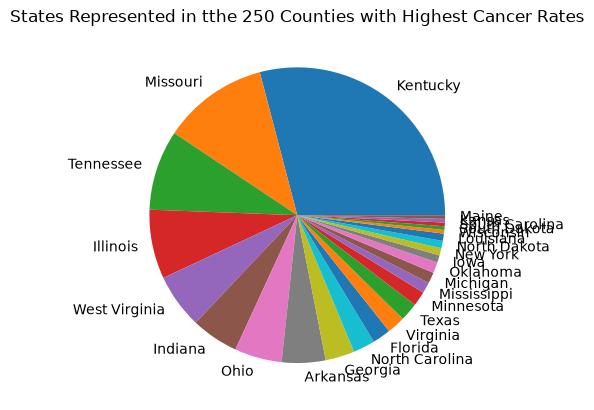

In [69]:
# Create pie chart showing which states have the most counties with high cancer rates

# First, sort by top 250
top_cancer_df=df.sort_values('cancer_rate', ascending=False)[:251] 

# Next, create pie chart based on new df
top_cancer_df.value_counts('state').plot(kind='pie', title="States Represented in tthe 250 Counties with Highest Cancer Rates")


<Axes: title={'center': 'States Represented in tthe 250 Counties with Highest PM2.5 Counts, 1999-2003'}, ylabel='state'>

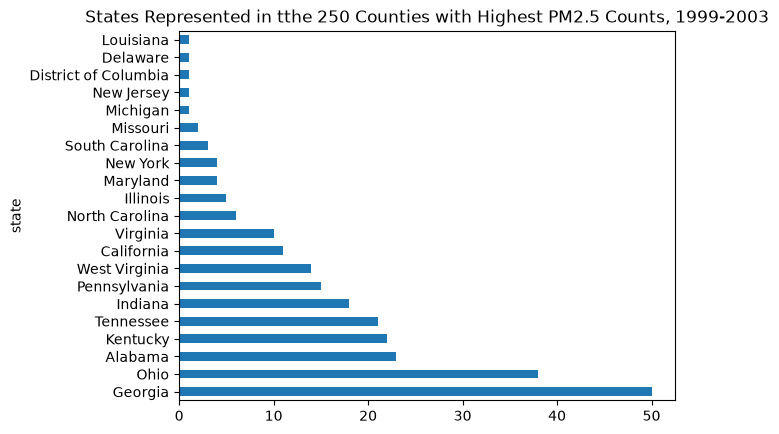

In [70]:
# Create bar chart showing which states have the most counties with high pollution concentrations

# First, find 250 counties with highest pollution concentrations
top_pollution_df=df.sort_values('pollution_concentration', ascending=False)[:251]

# Next, make chart
top_pollution_df.value_counts('state').plot(kind='barh', title="States Represented in tthe 250 Counties with Highest PM2.5 Counts, 1999-2003")


Text(0, 0.5, 'Average annual PM2.5 concentration')

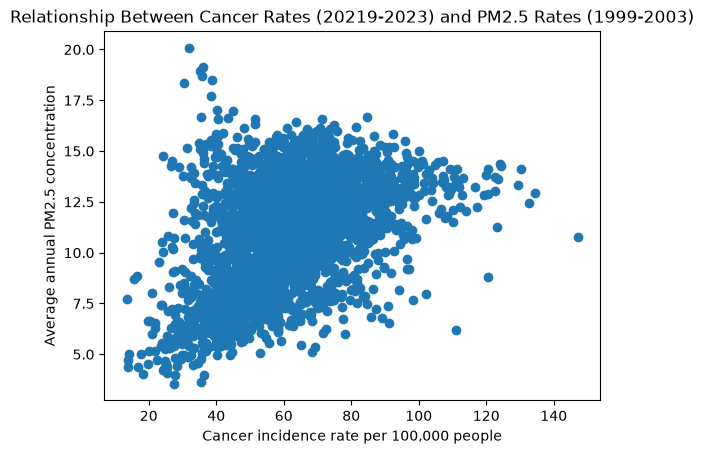

In [64]:
# Create scatterplot showing PM2.5 counts against cancer rates, for each county
import matplotlib.pyplot as plt
import numpy as np
x = df['cancer_rate'] 
y = df['pollution_count']
plt.scatter(x, y) # Generate scatter plot
plt.title("Relationship Between Cancer Rates (20219-2023) and PM2.5 Rates (1999-2003)")
plt.xlabel("Cancer incidence rate per 100,000 people")
plt.ylabel("Average annual PM2.5 concentration")
colors = {'Rural': '#FF5733', 'Urban': '#3357FF'} # I want to show rural and urban counties in different colors
